In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import openpyxl

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_excel('../../online_retail_II.xlsx', sheet_name= 0)

Exploratory Data Analysis

In [5]:
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
...,...,...,...,...,...,...,...,...
525456,538171,22271,FELTCRAFT DOLL ROSIE,2,2010-12-09 20:01:00,2.95,17530.0,United Kingdom
525457,538171,22750,FELTCRAFT PRINCESS LOLA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom
525458,538171,22751,FELTCRAFT PRINCESS OLIVIA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom
525459,538171,20970,PINK FLORAL FELTCRAFT SHOULDER BAG,2,2010-12-09 20:01:00,3.75,17530.0,United Kingdom


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[ns]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 32.1+ MB


In [7]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,525461.000000,525461,525461.000000,417534.000000
mean,10.337667,2010-06-28 11:37:36.845017856,4.688834,15360.645478
min,-9600.000000,2009-12-01 07:45:00,-53594.360000,12346.000000
25%,1.000000,2010-03-21 12:20:00,1.250000,13983.000000
50%,3.000000,2010-07-06 09:51:00,2.100000,15311.000000
75%,10.000000,2010-10-15 12:45:00,4.210000,16799.000000
max,19152.000000,2010-12-09 20:01:00,25111.090000,18287.000000
std,107.424110,NaN,146.126914,1680.811316


In [8]:
df.describe(include = 'O')

,Invoice,StockCode,Description,Country
count,525461,525461,522533,525461
unique,28816,4632,4681,40
top,537434,85123A,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom
freq,675,3516,3549,485852


In [9]:
df[df["Customer ID"].isna()].head(20)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom
577,489525,85226C,BLUE PULL BACK RACING CAR,1,2009-12-01 11:49:00,0.55,NaN,United Kingdom
578,489525,85227,SET/6 3D KIT CARDS FOR KIDS,1,2009-12-01 11:49:00,0.85,NaN,United Kingdom
1055,489548,22271,FELTCRAFT DOLL ROSIE,1,2009-12-01 12:32:00,2.95,NaN,United Kingdom
1056,489548,22254,FELT TOADSTOOL LARGE,12,2009-12-01 12:32:00,1.25,NaN,United Kingdom
1057,489548,22273,FELTCRAFT DOLL MOLLY,3,2009-12-01 12:32:00,2.95,NaN,United Kingdom
1058,489548,22195,LARGE HEART MEASURING SPOONS,1,2009-12-01 12:32:00,1.65,NaN,United Kingdom


In [10]:
df[df['Price'] < 0]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom


In [11]:
df[df['Quantity'] < 0].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


In [12]:
df['Invoice'] = df['Invoice'].astype('string')
df[df['Invoice'].str.match(r"^\d{6}$") == False]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
...,...,...,...,...,...,...,...,...
524695,C538123,22956,36 FOIL HEART CAKE CASES,-2,2010-12-09 15:41:00,2.10,12605.0,Germany
524696,C538124,M,Manual,-4,2010-12-09 15:43:00,0.50,15329.0,United Kingdom
524697,C538124,22699,ROSES REGENCY TEACUP AND SAUCER,-1,2010-12-09 15:43:00,2.95,15329.0,United Kingdom
524698,C538124,22423,REGENCY CAKESTAND 3 TIER,-1,2010-12-09 15:43:00,12.75,15329.0,United Kingdom


In [13]:
df['Invoice'].str.replace("[0-9]", "", regex = True).unique()

<StringArray>
['', 'C', 'A']
Length: 3, dtype: string

In [14]:
df[df['Invoice'].str.match(r'A')]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom


In [15]:
df['StockCode'] = df['StockCode'].astype('string')
df[(df['StockCode'].str.match(r'^\d{5}$') == False) & (df['StockCode'].str.match(r'^\d{5}[\a-zA-z]+$') == False)]['StockCode'].unique()

<StringArray>
[        'POST',            'D',     'DCGS0058',     'DCGS0068',
          'DOT',            'M',     'DCGS0004',     'DCGS0076',
           'C2', 'BANK CHARGES',     'DCGS0003',      'TEST001',
 'gift_0001_80',     'DCGS0072', 'gift_0001_20',     'DCGS0044',
      'TEST002', 'gift_0001_10', 'gift_0001_50',    'DCGS0066N',
 'gift_0001_30',         'PADS',       'ADJUST', 'gift_0001_40',
 'gift_0001_60', 'gift_0001_70', 'gift_0001_90',    'DCGSSGIRL',
     'DCGS0006',     'DCGS0016',     'DCGS0027',     'DCGS0036',
     'DCGS0039',     'DCGS0060',     'DCGS0056',     'DCGS0059',
         'GIFT',     'DCGSLBOY',            'm',     'DCGS0053',
     'DCGS0062',     'DCGS0037',     'DCGSSBOY',    'DCGSLGIRL',
            'S',     'DCGS0069',     'DCGS0070',     'DCGS0075',
            'B',     'DCGS0041',      'ADJUST2',           'C3',
       'SP1002',    'AMAZONFEE']
Length: 54, dtype: string

In [16]:
df_clean = df.copy()
df_clean.dropna(subset = ['Customer ID'], inplace=True)

In [17]:
invoice_mask = df_clean['Invoice'].str.match(r"^\d{6}$") == True
stock_code_mask = ((df_clean['StockCode'].str.match(r'^\d{5}$') == True) 
| (df_clean['StockCode'].str.match(r'^\d{5}[\a-zA-z]+$') == True) ) 
zero_price_mask = (df_clean['Price'] != 0)

In [18]:
df_clean = df_clean[(invoice_mask) & (stock_code_mask) & zero_price_mask]

In [19]:
df_clean.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,406295.000000,406295,406295.000000,406295.000000
mean,13.618359,2010-07-01 10:18:05.997415424,2.991771,15373.750194
min,1.000000,2009-12-01 07:45:00,0.030000,12346.000000
25%,2.000000,2010-03-26 14:01:00,1.250000,14006.000000
50%,5.000000,2010-07-09 15:48:00,1.950000,15326.000000
75%,12.000000,2010-10-14 17:09:00,3.750000,16814.000000
max,19152.000000,2010-12-09 20:01:00,295.000000,18287.000000
std,97.000476,NaN,4.285989,1677.333922


In [20]:
len(df_clean)/len(df)

0.7732162805612596

In [21]:
df_clean["SalesLineTotal"] = df_clean['Price'] * df_clean['Quantity']

In [22]:
aggregate_df = df_clean.groupby('Customer ID', as_index = False).agg(
    MonetaryValue = ('SalesLineTotal', 'sum'),
    Frequency = ('Invoice', 'nunique'),
    LastInvoiceDate = ('InvoiceDate', 'max')
)

In [23]:
aggregate_df

,Customer ID,MonetaryValue,Frequency,LastInvoiceDate
0,12346.0,169.36,2,2010-06-28 13:53:00
1,12347.0,1323.32,2,2010-12-07 14:57:00
2,12348.0,221.16,1,2010-09-27 14:59:00
3,12349.0,2221.14,2,2010-10-28 08:23:00
4,12351.0,300.93,1,2010-11-29 15:23:00
...,...,...,...,...
4280,18283.0,641.77,6,2010-11-22 15:30:00
4281,18284.0,411.68,1,2010-10-04 11:33:00
4282,18285.0,377.00,1,2010-02-17 10:24:00
4283,18286.0,1246.43,2,2010-08-20 11:57:00


In [24]:
max_invoice_date = aggregate_df['LastInvoiceDate'].max() 

In [25]:
aggregate_df['Recency'] = (max_invoice_date - aggregate_df['LastInvoiceDate']).dt.days

In [26]:
aggregate_df

,Customer ID,MonetaryValue,Frequency,LastInvoiceDate,Recency
0,12346.0,169.36,2,2010-06-28 13:53:00,164
1,12347.0,1323.32,2,2010-12-07 14:57:00,2
2,12348.0,221.16,1,2010-09-27 14:59:00,73
3,12349.0,2221.14,2,2010-10-28 08:23:00,42
4,12351.0,300.93,1,2010-11-29 15:23:00,10
...,...,...,...,...,...
4280,18283.0,641.77,6,2010-11-22 15:30:00,17
4281,18284.0,411.68,1,2010-10-04 11:33:00,66
4282,18285.0,377.00,1,2010-02-17 10:24:00,295
4283,18286.0,1246.43,2,2010-08-20 11:57:00,111


Histogram and Box Plots

<Axes: xlabel='Recency', ylabel='Count'>

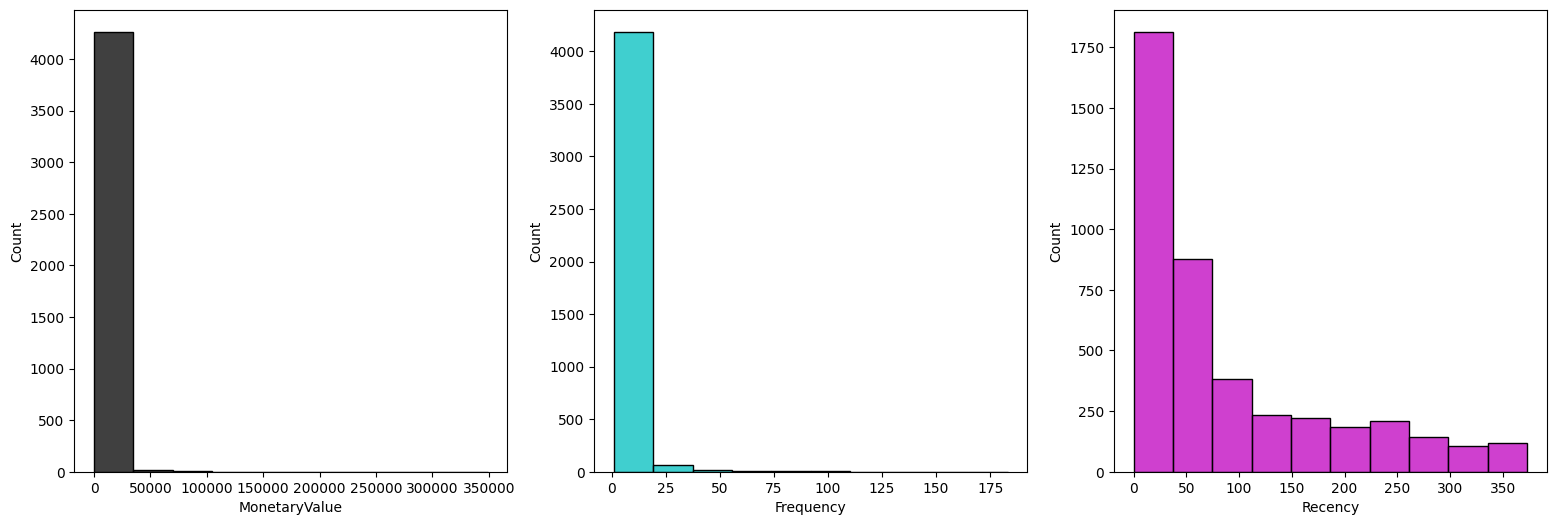

In [27]:
fig, ax = plt.subplots(1,3, figsize = (19,6))

sns.histplot(aggregate_df['MonetaryValue'], bins = 10, ax = ax[0], color = 'k')
sns.histplot(aggregate_df['Frequency'], bins = 10, ax = ax[1], color = 'c')
sns.histplot(aggregate_df['Recency'], bins = 10, ax = ax[2], color = 'm')

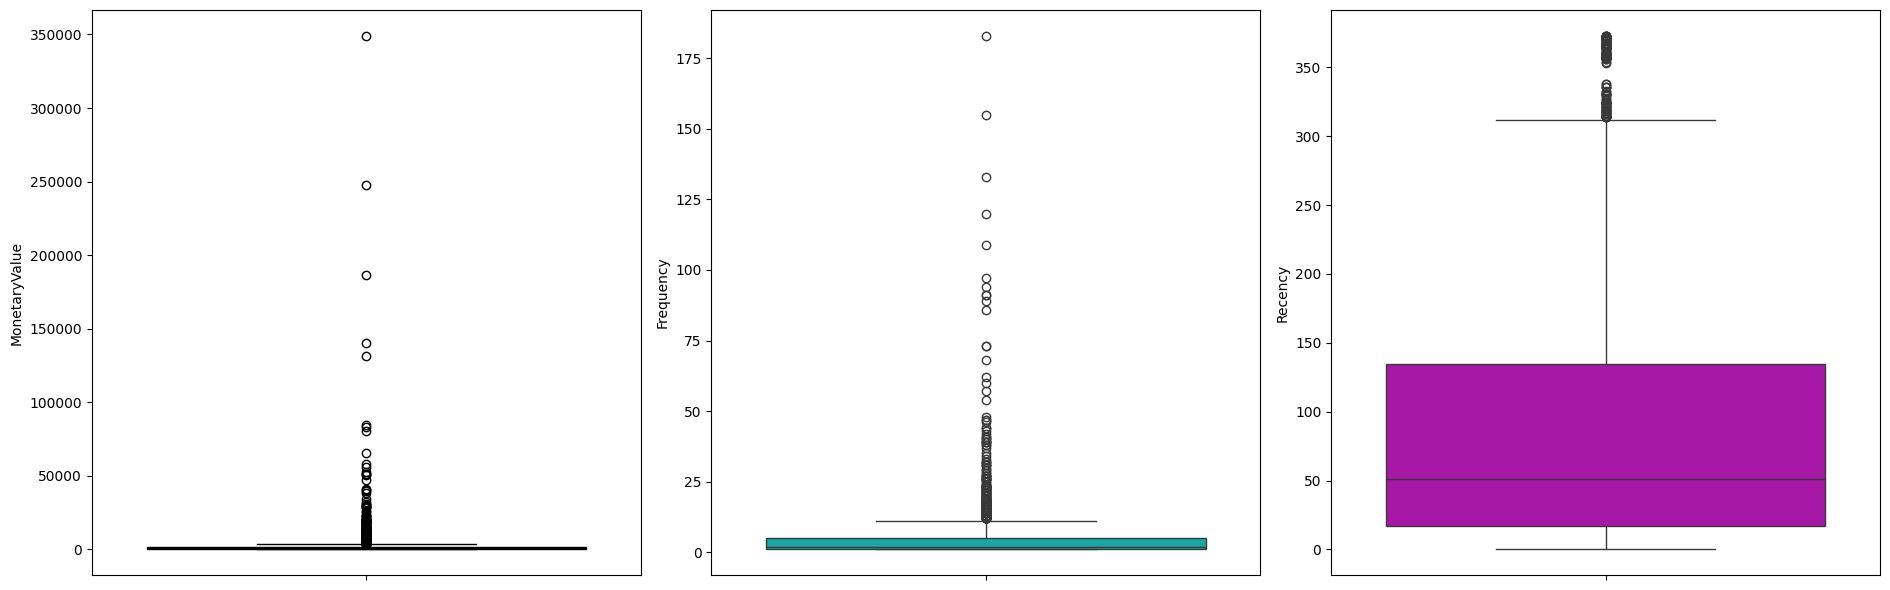

In [28]:
fig, ax = plt.subplots(1,3, figsize = (19,6))

sns.boxplot(aggregate_df['MonetaryValue'], ax = ax[0], color = 'k')
sns.boxplot(aggregate_df['Frequency'], ax = ax[1], color = 'c')
sns.boxplot(aggregate_df['Recency'], ax = ax[2], color = 'm')

plt.tight_layout()

Dealing With Outliers

In [29]:
monetary_q1 = aggregate_df['MonetaryValue'].quantile(0.25)
monetary_q3 = aggregate_df['MonetaryValue'].quantile(0.75)
monetary_iqr = monetary_q3 - monetary_q1

monetary_outliers_df = aggregate_df[((1.5 * monetary_iqr) + monetary_q3 <  aggregate_df['MonetaryValue']) | (aggregate_df['MonetaryValue'] < monetary_q1 - (1.5 *  monetary_iqr))]

In [30]:
frequency_q1 = aggregate_df['Frequency'].quantile(0.25)
frequency_q3 = aggregate_df['Frequency'].quantile(0.75)
frequency_iqr = frequency_q3 - frequency_q1

frequency_outliers_df = aggregate_df[((1.5 * frequency_iqr) + frequency_q3 <  aggregate_df['Frequency']) | (aggregate_df['Frequency'] < frequency_q1 - (1.5 *  frequency_iqr))]

In [31]:
non_outliers_df = aggregate_df[(~aggregate_df.index.isin(monetary_outliers_df.index)) & (~aggregate_df.index.isin(frequency_outliers_df.index))]

In [32]:
non_outliers_df.describe()

,Customer ID,MonetaryValue,Frequency,LastInvoiceDate,Recency
count,3809.000000,3809.000000,3809.000000,3809,3809.000000
mean,15376.482804,885.502195,2.863481,2010-09-03 11:16:46.516146176,97.082174
min,12346.000000,1.550000,1.000000,2009-12-01 10:49:00,0.000000
25%,13912.000000,279.910000,1.000000,2010-07-08 14:48:00,22.000000
50%,15389.000000,588.050000,2.000000,2010-10-12 16:25:00,58.000000
75%,16854.000000,1269.050000,4.000000,2010-11-17 13:14:00,154.000000
max,18287.000000,3788.210000,11.000000,2010-12-09 20:01:00,373.000000
std,1693.199806,817.672280,2.243748,NaN,98.111495


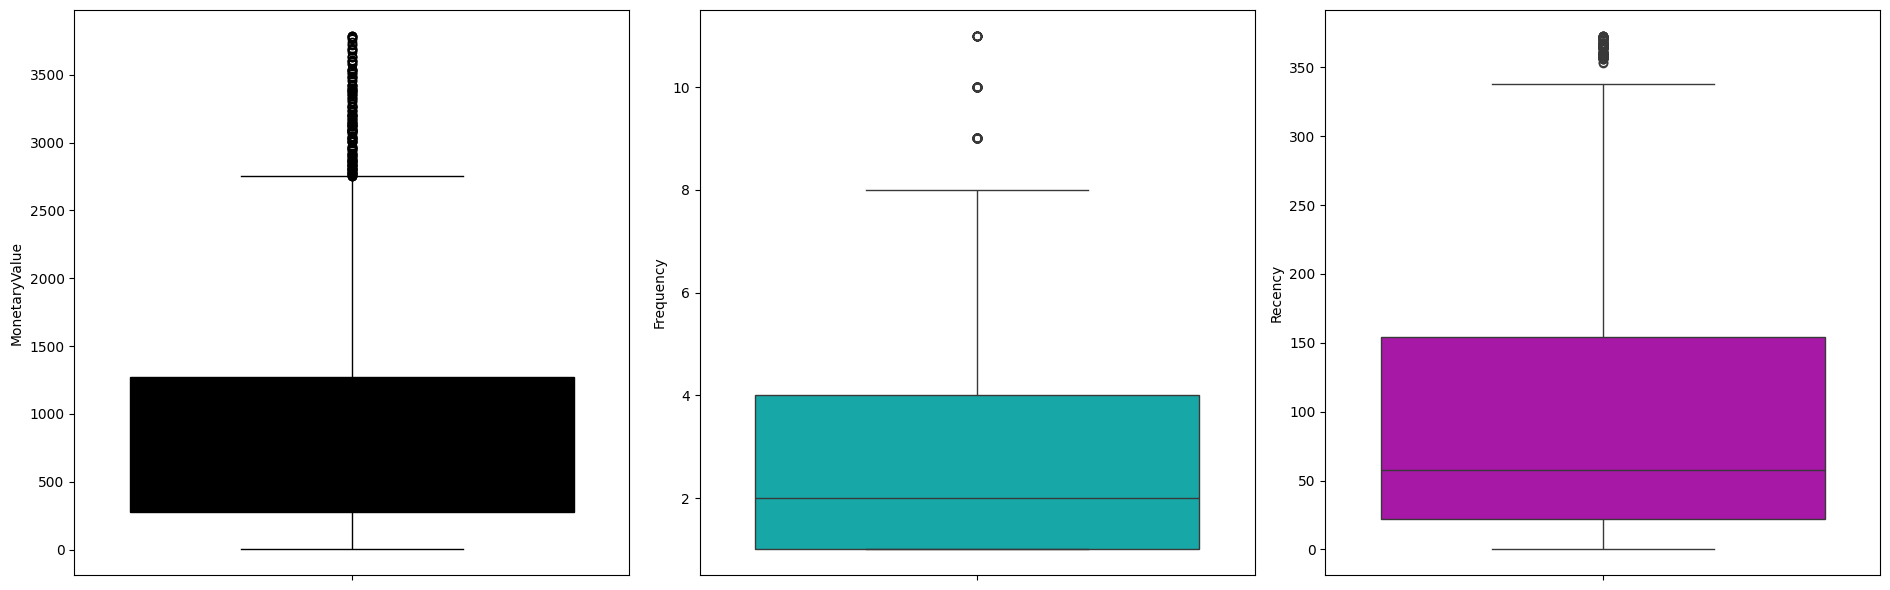

In [33]:
fig, ax = plt.subplots(1,3, figsize = (19,6))

sns.boxplot(non_outliers_df['MonetaryValue'], ax = ax[0], color = 'k')
sns.boxplot(non_outliers_df['Frequency'], ax = ax[1], color = 'c')
sns.boxplot(non_outliers_df['Recency'], ax = ax[2], color = 'm')

plt.tight_layout()

Scaling and Visulaising the Data

In [34]:
scaler = StandardScaler() 
scaled = scaler.fit_transform(non_outliers_df[['MonetaryValue', 'Frequency', 'Recency']])
scaled_non_outliers_df = pd.DataFrame(scaled, columns = ['MonetaryValue', 'Frequency', 'Recency'])

Text(0.5, 0, 'Recency')

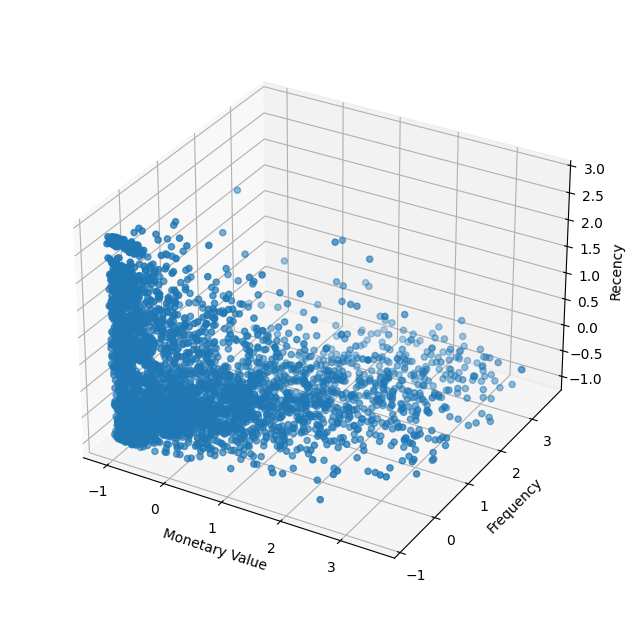

In [35]:
fig, ax = plt.subplots(subplot_kw={'projection':'3d'}, figsize = (12,8))
ax.scatter(scaled_non_outliers_df['MonetaryValue'], scaled_non_outliers_df['Frequency'], scaled_non_outliers_df['Recency'])
ax.set_box_aspect(None, zoom=0.9)
ax.set_xlabel('Monetary Value')
ax.set_ylabel('Frequency')
ax.set_zlabel('Recency')


Selecting the Number of Clusters

Text(0, 0.5, 'Inertia')

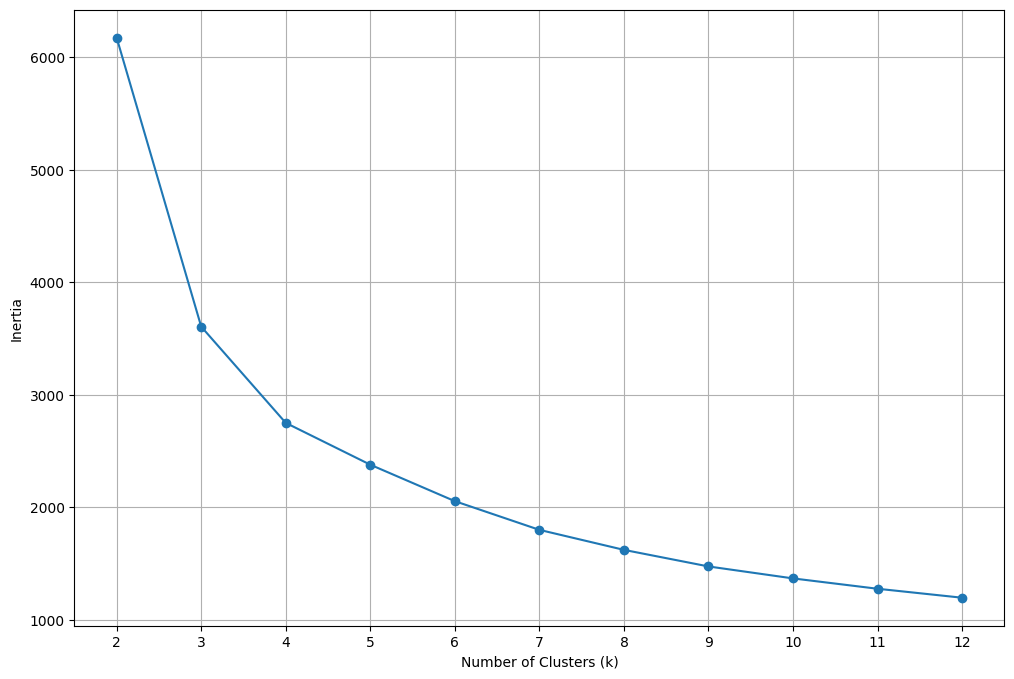

In [37]:
k = 12 

inertia = []
for i in range(2,k+1): 
    km = KMeans(n_clusters=i, max_iter=1000, random_state=42, n_init = 100 )
    km.fit(scaled_non_outliers_df)
    inertia.append(km.inertia_)

plt.figure(figsize=(12,8))
plt.grid(True)
plt.xticks(range(2, 13))
plt.plot(range(2,k+1),inertia, marker = 'o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')

For n_clusters = 2 The average silhouette_score is : 0.4436173966582607
For n_clusters = 3 The average silhouette_score is : 0.4584688357803814
For n_clusters = 4 The average silhouette_score is : 0.4154918124565326
For n_clusters = 5 The average silhouette_score is : 0.40544159476485675


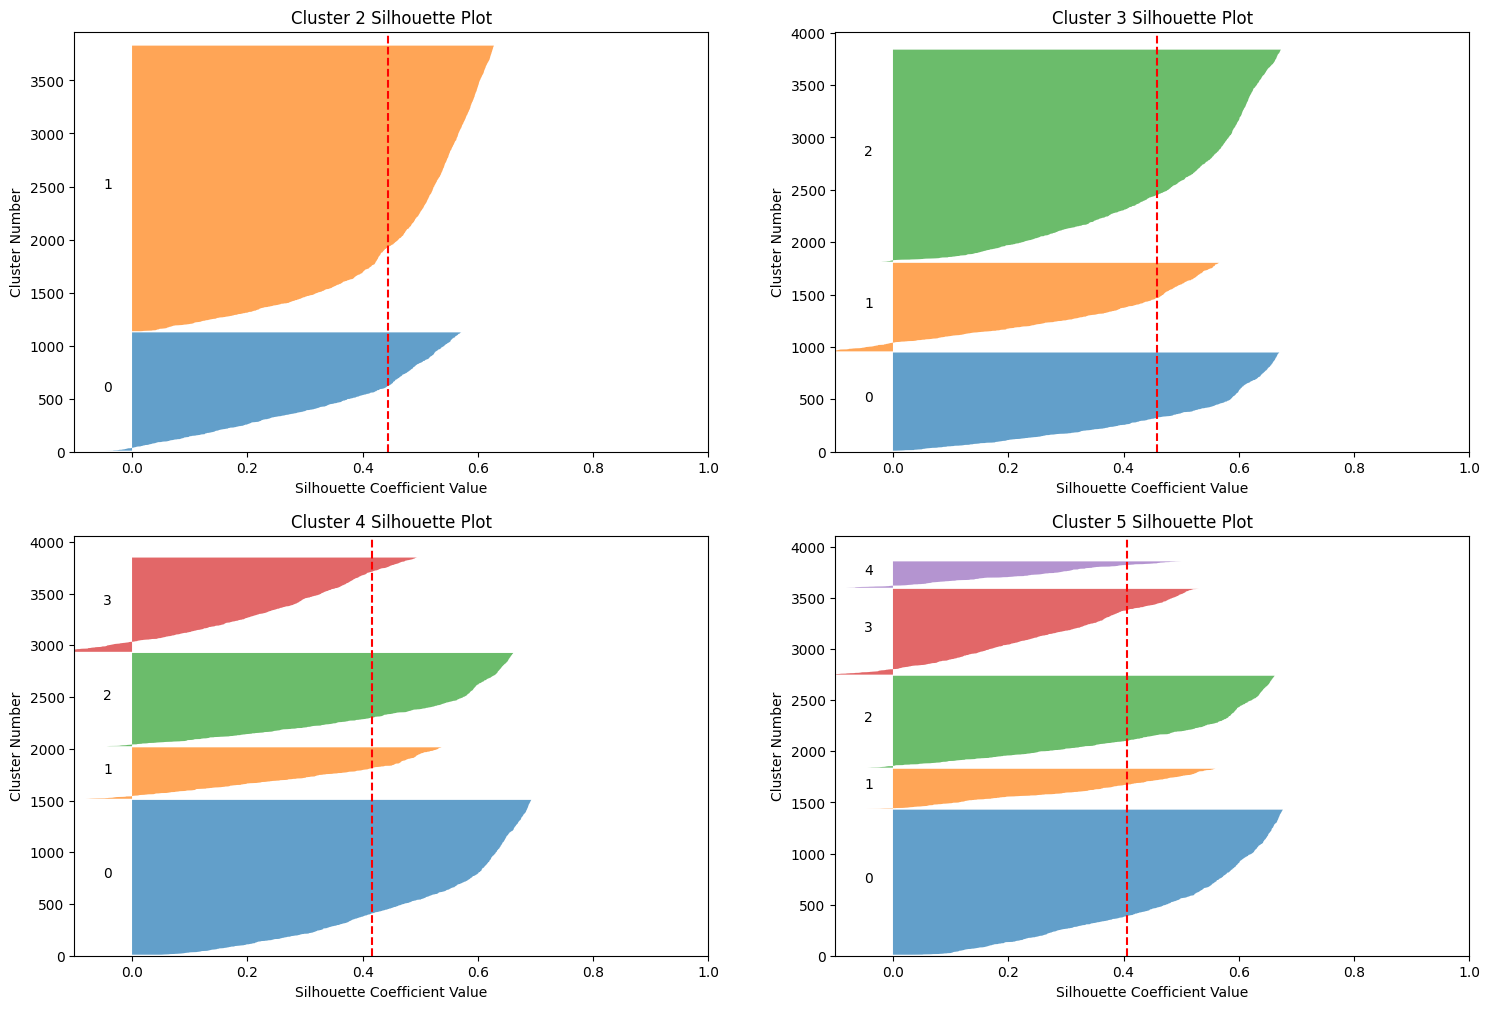

In [38]:
import matplotlib.cm as cm

fig, axes = plt.subplots(2,2, figsize = (18,12))

clusters = [2,3,4,5]
for n in clusters : 
    ax = axes.flat[n-2]
    ax.set_ylim([0, len(scaled_non_outliers_df) + (n + 1) * 50])
    ax.set_xlim([-0.1, 1])

    km = KMeans(n_clusters=n, max_iter=1000, random_state=42, n_init = 100 )
    cluster_labels = km.fit_predict(scaled_non_outliers_df)

    silhouette_avg = silhouette_score(scaled_non_outliers_df, cluster_labels)
    print(
        "For n_clusters =",
        n,
        "The average silhouette_score is :",
        silhouette_avg,)

    sample_silhouette_values = silhouette_samples(scaled_non_outliers_df, cluster_labels)
    y_lower = 10 
    for i in range(n): 
        cluster_i_silhouette_values = sample_silhouette_values[cluster_labels == i]
        cluster_i_silhouette_values.sort()
        size_cluster_i = cluster_i_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i
        ax.fill_betweenx((np.arange(y_lower,y_upper)), 0, cluster_i_silhouette_values, alpha = 0.7)
        ax.text(-0.05, y_lower + 0.5*size_cluster_i, str(i))
        y_lower = y_upper + 10


    ax.axvline(silhouette_avg, color = "red", linestyle = '--')
    ax.set_ylabel('Cluster Number')
    ax.set_xlabel('Silhouette Coefficient Value')
    ax.set_title('Cluster {} Silhouette Plot'.format(n))
    



Visualising the Final Cluster Allocation / Cluster Analysis

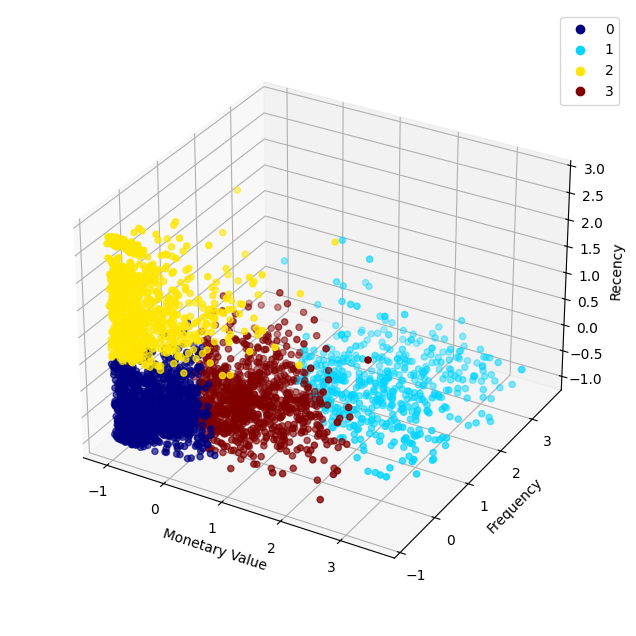

In [39]:
km_final = KMeans(n_clusters=4, max_iter=1000, random_state=42, n_init = 100 )
final_cluster_labels = km_final.fit_predict(scaled_non_outliers_df)

fig, ax = plt.subplots(subplot_kw={'projection':'3d'}, figsize = (12,8))
scatter_plot = ax.scatter(scaled_non_outliers_df['MonetaryValue'], scaled_non_outliers_df['Frequency'], scaled_non_outliers_df['Recency'], cmap = 'jet' , c = final_cluster_labels)
ax.set_box_aspect(None, zoom=0.9)
ax.set_xlabel('Monetary Value')
ax.set_ylabel('Frequency')
ax.set_zlabel('Recency')
handles, _ = scatter_plot.legend_elements()
ax.legend(handles=handles,labels = [0,1,2,3])



In [40]:
cmap = plt.get_cmap('jet')
norm = plt.Normalize(0,3)
palette = {i: cmap(norm(i)) for i in range(4)}

In [41]:
non_outliers_df["Cluster"] = final_cluster_labels

/var/folders/cj/xxjbngpn6cz_f1tsy7q28dvh0000gn/T/ipykernel_93499/1303249629.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  non_outliers_df["Cluster"] = final_cluster_labels


<Axes: xlabel='Cluster', ylabel='Recency'>

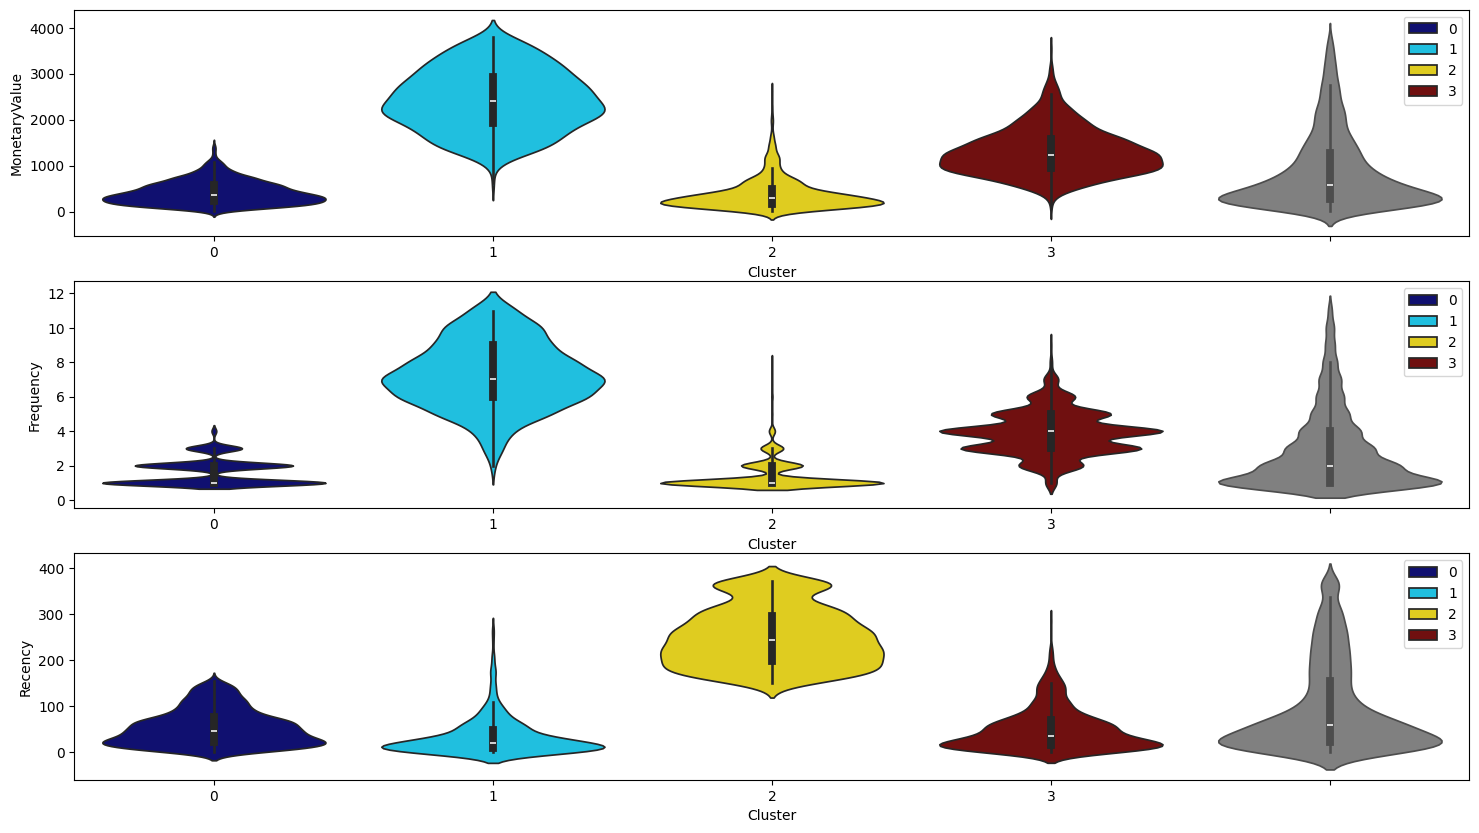

In [42]:
fig, ax = plt.subplots(3,1, figsize = (18,10))
sns.violinplot(x=  non_outliers_df['Cluster'], y = non_outliers_df['MonetaryValue'], hue = non_outliers_df['Cluster'], palette = palette, ax = ax.flat[0])
sns.violinplot(y = non_outliers_df['MonetaryValue'], color = 'gray', ax = ax.flat[0])

sns.violinplot(x= non_outliers_df['Cluster'], y = non_outliers_df['Frequency'], hue = non_outliers_df['Cluster'], palette = palette, ax = ax.flat[1])
sns.violinplot(y = non_outliers_df['Frequency'], color = 'gray', ax = ax.flat[1])

sns.violinplot(x= non_outliers_df['Cluster'], y = non_outliers_df['Recency'], hue = non_outliers_df['Cluster'], palette = palette, ax = ax.flat[2])
sns.violinplot(y = non_outliers_df['Recency'], color = 'gray', ax = ax.flat[2])


Outlier Analysis and Full Data View

In [43]:
overlap_indicies = monetary_outliers_df.index.intersection(frequency_outliers_df.index)

monetary_only_outliers_df = monetary_outliers_df.drop(overlap_indicies)
frequency_only_outliers_df = frequency_outliers_df.drop(overlap_indicies)
monetary_and_frequency_outliers_df = monetary_outliers_df.loc[overlap_indicies]

monetary_only_outliers_df['Cluster'] = -1
frequency_only_outliers_df['Cluster'] = -2
monetary_and_frequency_outliers_df['Cluster'] = -3

outliers_df = pd.concat((monetary_only_outliers_df, frequency_only_outliers_df, monetary_and_frequency_outliers_df))

<Axes: xlabel='Cluster', ylabel='Recency'>

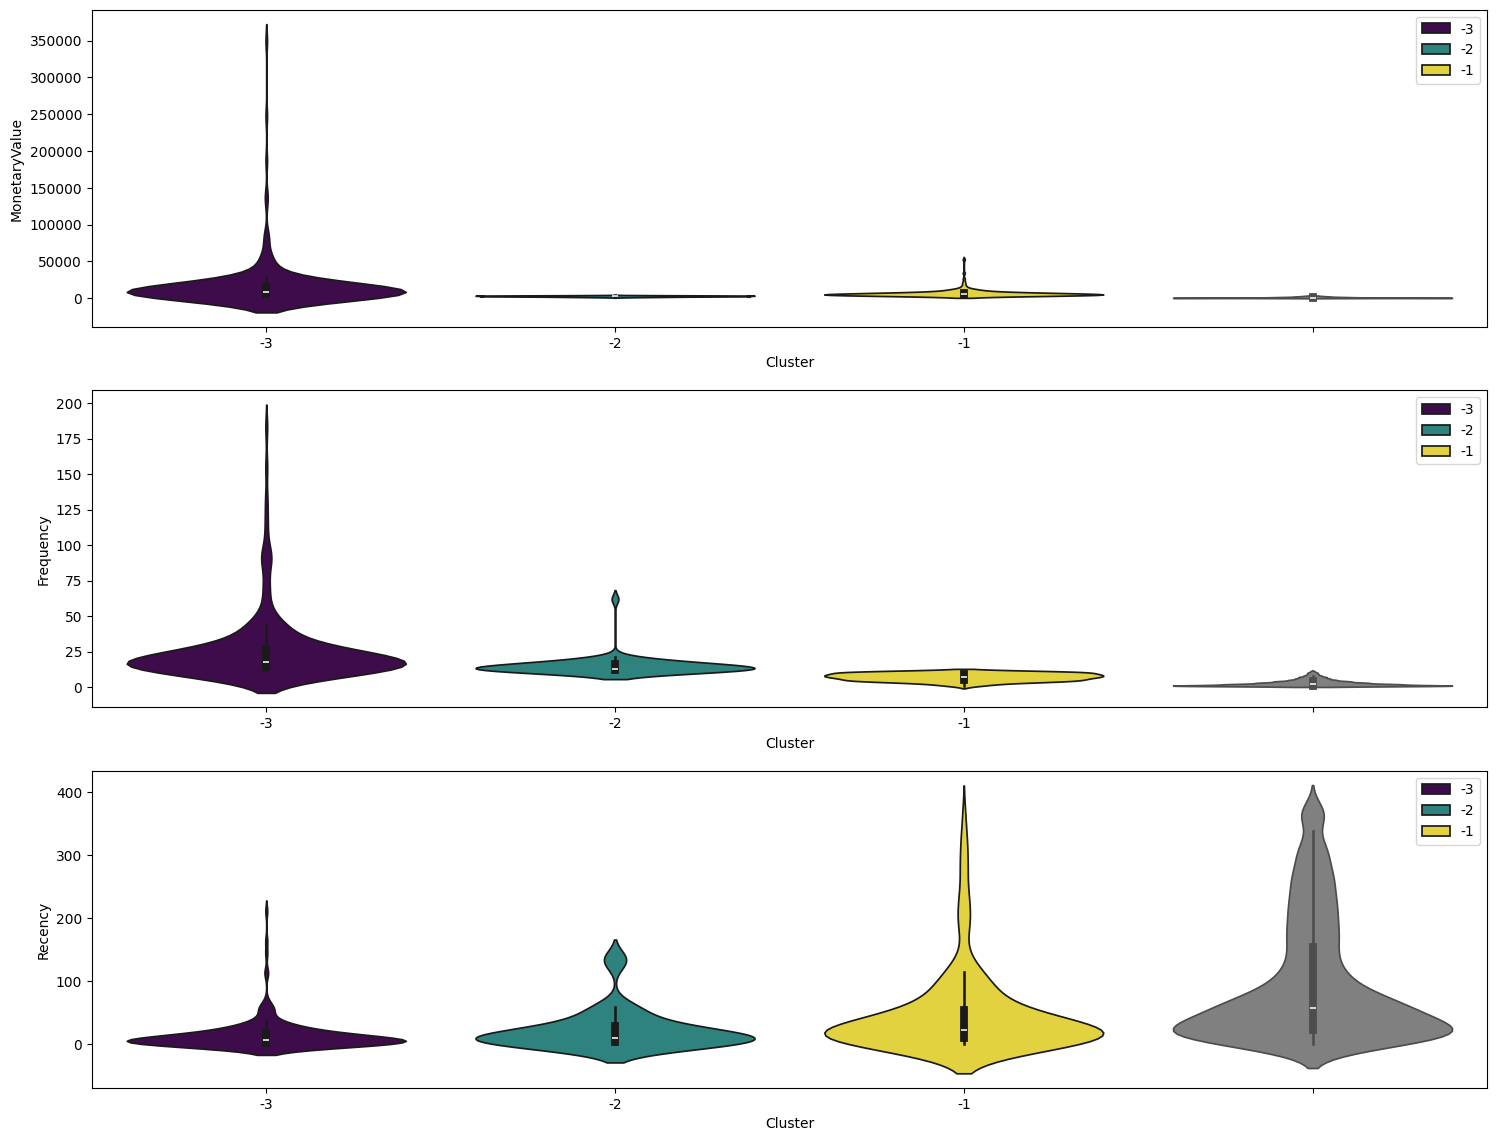

In [44]:
fig, ax = plt.subplots(3,1, figsize = (18,14))


sns.violinplot(x = outliers_df['Cluster'], y = outliers_df['MonetaryValue'], hue = outliers_df['Cluster'], palette = 'viridis', ax = ax.flat[0])
sns.violinplot(y = non_outliers_df['MonetaryValue'], color = 'gray', ax = ax.flat[0])


sns.violinplot(x = outliers_df['Cluster'], y = outliers_df['Frequency'], hue = outliers_df['Cluster'], palette = 'viridis', ax = ax.flat[1] )
sns.violinplot(y = non_outliers_df['Frequency'], color = 'gray', ax = ax.flat[1])

sns.violinplot(x = outliers_df['Cluster'], y = outliers_df['Recency'], hue = outliers_df['Cluster'], palette = 'viridis', ax = ax.flat[2] )
sns.violinplot(y = non_outliers_df['Recency'], color = 'gray', ax = ax.flat[2])

In [49]:
labels = {
    0 : '(1)',
    1 : '(2)',
    2 : '(3)',
    3 : '(4)',
    -1 : 'M',
    -2 : 'F',
    -3 : 'M&F',
}


In [50]:
cluster_df = pd.concat((non_outliers_df, outliers_df ))

In [51]:
cluster_df['Cluster'] = cluster_df['Cluster'].map(labels)

<Axes: xlabel='Cluster'>

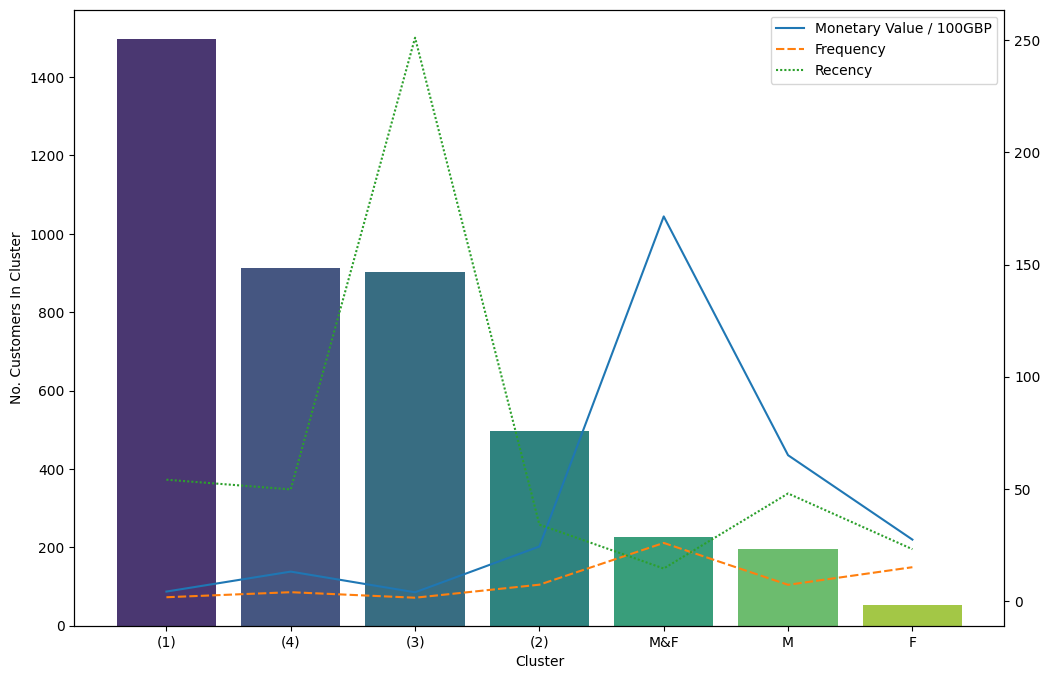

In [52]:
cluster_counts = cluster_df["Cluster"].value_counts()
cluster_df['Monetary Value / 100GBP'] = cluster_df['MonetaryValue'] / 100
feature_means = cluster_df.groupby('Cluster')[['Monetary Value / 100GBP', 'Frequency', 'Recency']].mean()

fig, ax = plt.subplots(figsize = (12,8)) 
sns.barplot(x = cluster_counts.index, y = cluster_counts.values, ax = ax, hue = cluster_counts.index, palette = 'viridis')
ax2 = ax.twinx()
ax.set_ylabel("No. Customers In Cluster")

sns.lineplot(data = feature_means, ax = ax2 )
 